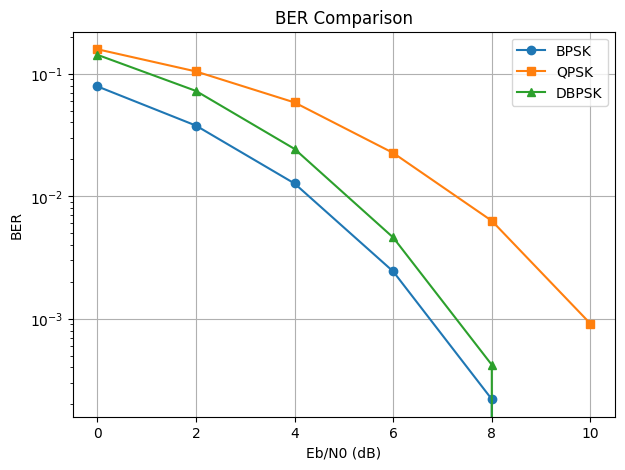

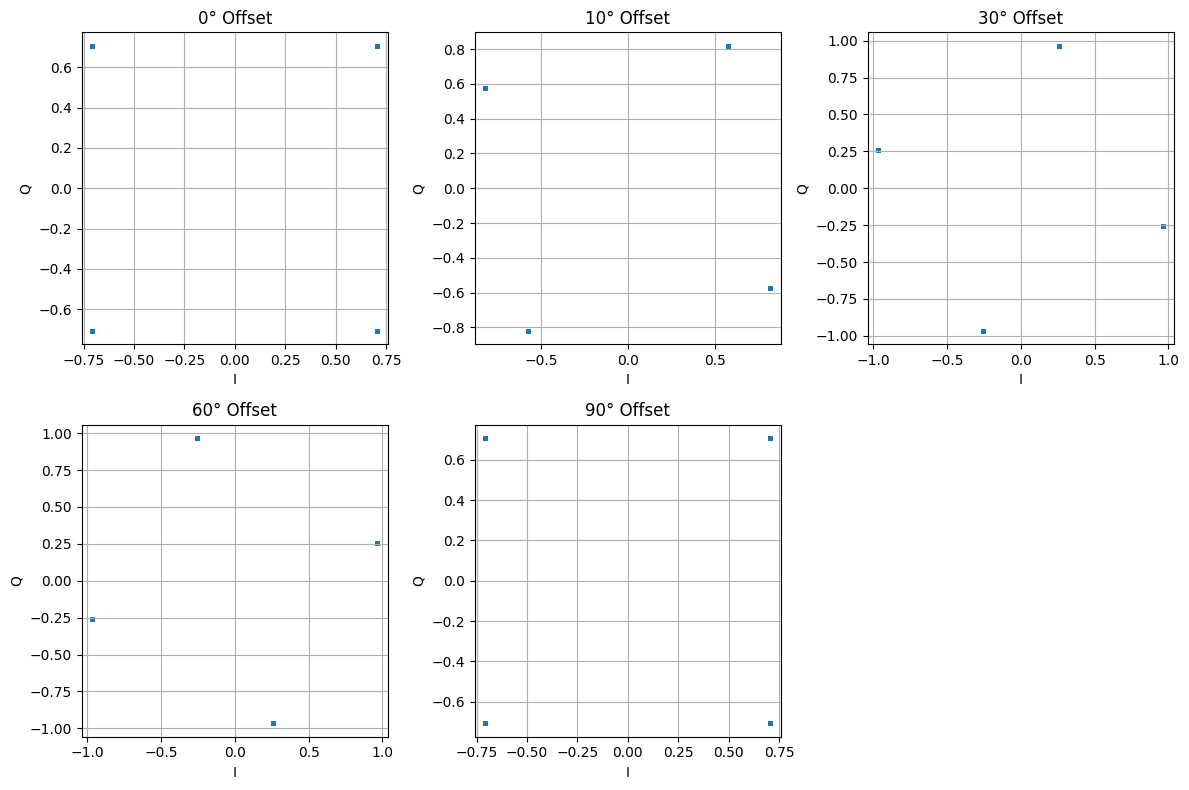


Gray-coded QPSK Mapping:
[0 0]  -->  (0.7071067811865475+0.7071067811865475j)
[0 1]  -->  (-0.7071067811865475+0.7071067811865475j)
[1 1]  -->  (-0.7071067811865475-0.7071067811865475j)
[1 0]  -->  (0.7071067811865475-0.7071067811865475j)

Original bits:
[0 1 1 0 1 0 0 0 0 1 0 1 1 1 1 1 1 1 1 1]

Differential encoded:
[0 1 0 0 1 1 1 1 1 0 0 1 0 1 0 1 0 1 0 1]

Recovered bits:
[0 1 1 0 1 0 0 0 0 1 0 1 1 1 1 1 1 1 1 1]


In [2]:

# ============================================================
# Experiment 10: BPSK, Gray-coded QPSK and DBPSK
# From First Principles
# Demonstrates:
# 1. Normalized BPSK
# 2. Gray-coded QPSK
# 3. DBPSK
# 4. Carrier phase offset effect
# 5. BER comparison
# 6. Constellation diagrams
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ============================================================
# Parameters
# ============================================================
Nbits = 100000
EbN0_dB = np.arange(0, 11, 2)
phase_offsets_deg = [0, 10, 30, 60, 90]

# ============================================================
# AWGN Channel
# ============================================================
def awgn(signal, snr_db):
    snr = 10**(snr_db/10)
    noise_var = 1/(2*snr)

    if np.iscomplexobj(signal):
        noise = np.sqrt(noise_var) * (
            np.random.randn(len(signal)) +
            1j*np.random.randn(len(signal))
        )
    else:
        noise = np.sqrt(noise_var) * np.random.randn(len(signal))

    return signal + noise

# ============================================================
# BPSK
# ============================================================
def bpsk_mod(bits):
    return 2*bits - 1      # 0→-1, 1→+1

def bpsk_demod(rx):
    return (rx > 0).astype(int)

# ============================================================
# Gray-coded QPSK
# Mapping:
# 00 -> +1 +j
# 01 -> -1 +j
# 11 -> -1 -j
# 10 -> +1 -j
# Normalized by sqrt(2)
# ============================================================
def qpsk_mod(bits):

    bits = bits.reshape(-1,2)

    mapping = {
        (0,0): (1+1j),
        (0,1): (-1+1j),
        (1,1): (-1-1j),
        (1,0): (1-1j)
    }

    symbols = np.array(
        [mapping[tuple(b)] for b in bits]
    )

    return symbols / np.sqrt(2)

def qpsk_demod(symbols):

    I = np.real(symbols)
    Q = np.imag(symbols)

    bits = []

    for i,q in zip(I,Q):

        if i>0 and q>0:
            bits.extend([0,0])

        elif i<0 and q>0:
            bits.extend([0,1])

        elif i<0 and q<0:
            bits.extend([1,1])

        else:
            bits.extend([1,0])

    return np.array(bits)

# ============================================================
# DBPSK
# ============================================================
def dbpsk_encode(bits):

    out = np.zeros(len(bits), dtype=int)

    prev = 0

    for i,b in enumerate(bits):

        if b==1:
            prev ^= 1

        out[i] = prev

    return out

def dbpsk_decode(bits):

    out = np.zeros(len(bits), dtype=int)

    prev = 0

    for i,b in enumerate(bits):

        out[i] = b ^ prev
        prev = b

    return out

# ============================================================
# Phase Offset
# ============================================================
def phase_rotate(signal, deg):

    theta = np.deg2rad(deg)

    return signal * np.exp(1j*theta)

# ============================================================
# BER Simulation
# ============================================================
BER_BPSK = []
BER_QPSK = []
BER_DBPSK = []

for snr in EbN0_dB:

    # -----------------------
    # BPSK
    # -----------------------
    bits = np.random.randint(0,2,Nbits)

    tx = bpsk_mod(bits)

    rx = awgn(tx, snr)

    det = bpsk_demod(rx)

    ber = np.mean(bits != det)

    BER_BPSK.append(ber)

    # -----------------------
    # QPSK
    # -----------------------
    bits_q = np.random.randint(0,2,Nbits)

    tx_q = qpsk_mod(bits_q)

    rx_q = awgn(tx_q, snr)

    det_q = qpsk_demod(rx_q)

    ber_q = np.mean(bits_q != det_q)

    BER_QPSK.append(ber_q)

    # -----------------------
    # DBPSK
    # -----------------------
    bits_d = np.random.randint(0,2,Nbits)

    enc = dbpsk_encode(bits_d)

    tx_d = bpsk_mod(enc)

    rx_d = awgn(tx_d, snr)

    hard = bpsk_demod(rx_d)

    dec = dbpsk_decode(hard)

    ber_d = np.mean(bits_d != dec)

    BER_DBPSK.append(ber_d)

# ============================================================
# BER Plot
# ============================================================
plt.figure(figsize=(7,5))

plt.semilogy(EbN0_dB, BER_BPSK,'o-',label='BPSK')
plt.semilogy(EbN0_dB, BER_QPSK,'s-',label='QPSK')
plt.semilogy(EbN0_dB, BER_DBPSK,'^-',label='DBPSK')

plt.grid(True)
plt.xlabel("Eb/N0 (dB)")
plt.ylabel("BER")
plt.title("BER Comparison")
plt.legend()
plt.show()

# ============================================================
# Phase Offset Effect
# ============================================================
bits = np.random.randint(0,2,2000)
tx = qpsk_mod(bits)

plt.figure(figsize=(12,8))

for i,ph in enumerate(phase_offsets_deg):

    rx = phase_rotate(tx, ph)

    plt.subplot(2,3,i+1)

    plt.scatter(np.real(rx),
                np.imag(rx),
                s=5)

    plt.grid(True)
    plt.axis('equal')

    plt.title(f"{ph}° Offset")
    plt.xlabel("I")
    plt.ylabel("Q")

plt.tight_layout()
plt.show()

# ============================================================
# QPSK Mapping Verification
# ============================================================
test_bits = np.array([
    0,0,
    0,1,
    1,1,
    1,0
])

symbols = qpsk_mod(test_bits)

print("\nGray-coded QPSK Mapping:")
for i,s in enumerate(symbols):

    pair = test_bits[2*i:2*i+2]

    print(pair, " --> ", s)

# ============================================================
# Differential Detection Example
# ============================================================
bits = np.random.randint(0,2,20)

enc = dbpsk_encode(bits)

print("\nOriginal bits:")
print(bits)

print("\nDifferential encoded:")
print(enc)

decoded = dbpsk_decode(enc)

print("\nRecovered bits:")
print(decoded)